# 5 · Numerics guide: accuracy, speed, warnings

**What you will learn:** how the numerical settings — order, grid size `N`, binning `n_bin`, integration rule, tolerances — trade accuracy against run time, how to read PyToF's warnings, and how to debug a calculation that does not converge.

All numbers in this notebook are measured live on the Wisdom & Hubbard (2016) Jupiter polytrope of notebook 1, for which the exact solution is known (`accuracy/references.py`). Run times depend on your machine; the *ratios* are what matters. More complete studies are in `accuracy/`.

In [1]:
import sys
import os
import pathlib
import tempfile
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

# Optional personal matplotlib style: used if a file mpl_config.py exists in a
# folder above this one, silently ignored otherwise.
for parent in pathlib.Path.cwd().resolve().parents[:4]:
    if (parent / "mpl_config.py").exists():
        sys.path.insert(0, str(parent))
        break
try:
    from mpl_config import apply_mpl_opts

    apply_mpl_opts()
except ImportError:
    pass  # plain matplotlib defaults

from PyToF import ToF
from PyToF.messages import ConvergenceWarning, PyToFWarning, RenamedWarning
from tutorial_utils import Bessel, JUPITER_RADIUS


def run(N=1024, order=4, repeat=3, **options):
    """Relax the W&H Jupiter polytrope; returns (model, best run time in s, iterations)."""
    X = ToF(N=N, order=order, R_ref=JUPITER_RADIUS, **options)
    X.set_barotrope(lambda P, param: np.sqrt(P))
    best = np.inf
    for _ in range(repeat):
        X.reset()
        tic = time.perf_counter()
        iterations = X.relax_to_barotrope()
        best = min(best, time.perf_counter() - tic)
    return X, best, iterations


def rel_error(X, n):
    """Relative error of J_2n against the exact solution."""
    return abs(X.Js[n] / Bessel[n] - 1)

## Order and grid size: accuracy versus time

Each point is one (order, $N$) combination, with $N = 2^5 \ldots 2^{12}$. The $x$ axis is the time of one complete `relax_to_barotrope()`, the $y$ axis the error of $J_2$, $J_4$ or $J_6$:

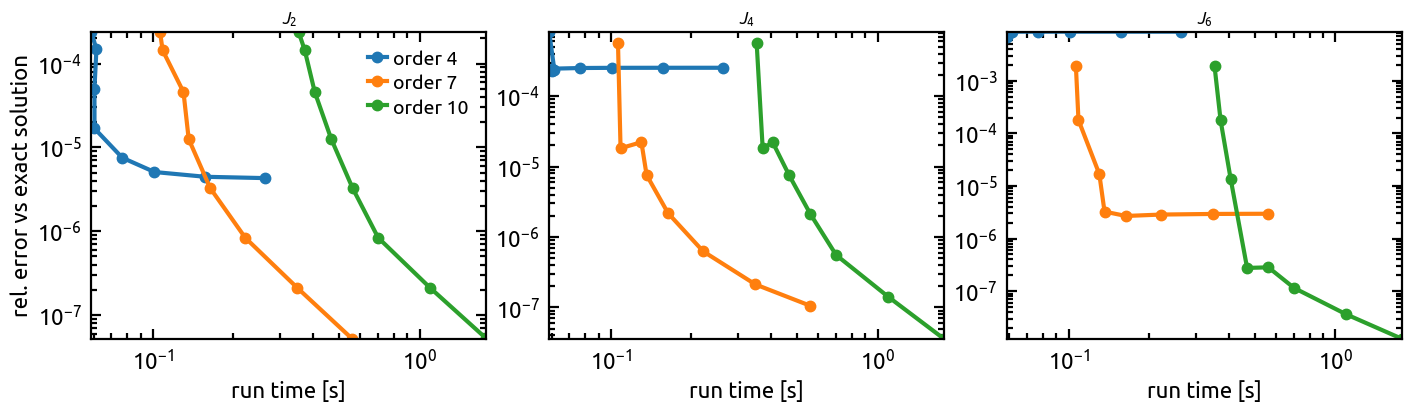

In [2]:
orders = [4, 7, 10]
Ns = [2**k for k in range(5, 13)]
results = {}
for order in orders:
    for N in Ns:
        X, t, it = run(N, order, repeat=1 if N > 1024 else 3)
        results[order, N] = (t, [rel_error(X, n) for n in (1, 2, 3)])

fig, axs = plt.subplots(1, 3, figsize=(14, 4), layout="constrained", sharex=True)
for order in orders:
    t = [results[order, N][0] for N in Ns]
    for k, ax in enumerate(axs):
        ax.plot(t, [results[order, N][1][k] for N in Ns], "o-", label=f"order {order}")
for k, ax in enumerate(axs, start=1):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("run time [s]")
    ax.set_title(f"$J_{{{2 * k}}}$")
axs[0].set_ylabel("rel. error vs exact solution")
axs[0].legend(frameon=False)

Read it as a cost–accuracy curve: from the left (small $N$) to the right (large $N$) the error falls until it flattens at the floor of the order. For a given target error, take the leftmost curve that gets there. For the three moments shown:

In [3]:
print("cheapest (order, N) reaching a given error for J2 / J4 / J6   [time]")
for target in (1e-3, 1e-4, 1e-5, 1e-6):
    line = []
    for k in range(3):
        best = min(((results[o, N][0], o, N) for o in orders for N in Ns if results[o, N][1][k] < target), default=None)
        line.append(f"{'--':>18s}" if best is None else f"order {best[1]:2d}, N={best[2]:5d} [{best[0]:.2f}s]")
    print(f"error < {target:.0e}: " + " | ".join(line))

cheapest (order, N) reaching a given error for J2 / J4 / J6   [time]
error < 1e-03: order  4, N=   32 [0.06s] | order  4, N=   32 [0.06s] | order  7, N=   64 [0.11s]
error < 1e-04: order  4, N=  128 [0.06s] | order  7, N=   64 [0.11s] | order  7, N=  128 [0.13s]
error < 1e-05: order  4, N=  512 [0.08s] | order  7, N=  256 [0.14s] | order  7, N=  256 [0.14s]
error < 1e-06: order  7, N= 1024 [0.22s] | order  7, N= 1024 [0.22s] | order 10, N=  256 [0.47s]


Run times grow with the order (order 10 is five to six times slower than order 4 at the same $N$) and, above a few hundred points, with $N$. Below that, a calculation is dominated by a fixed cost per iteration, so going from 64 to 512 points costs little time, especially at low order.

## Binning: `n_bin`

The slowest step of the Theory of Figures, the update of the figure functions, can be computed on a coarser grid of `n_bin` points and interpolated back (`n_bin=-1`, the default, uses all `N` points). This helps most at high order and large $N$, where that step dominates the run time. Time and error for $N=4096$, 10th order:

In [4]:
N = 4096
print(f"{'N/n_bin':>8s}{'time [s]':>10s}{'err J2':>10s}{'err J4':>10s}{'err J6':>10s}")
for factor in (1, 4, 16, 64, 256):
    X, t, it = run(N, 10, n_bin=N // factor, repeat=2)
    print(f"{factor:8d}{t:10.2f}{rel_error(X, 1):10.1e}{rel_error(X, 2):10.1e}{rel_error(X, 3):10.1e}")

 N/n_bin  time [s]    err J2    err J4    err J6


       1      1.71   5.3e-08   3.6e-08   1.2e-08


       4      1.29   5.3e-08   3.6e-08   1.2e-08


      16      0.97   4.5e-08   2.3e-08   3.6e-09


      64      0.83   1.3e-06   1.8e-07   7.4e-06


     256      0.80   5.2e-05   8.9e-04   3.4e-03


Binning by a factor of up to 16 costs nothing in accuracy (the errors are even unchanged to the digits shown) and saves about 40% of the time here; beyond a factor of about 64 the interpolation error takes over. The time stops falling at about half of the unbinned value because the rest of the calculation (pressures, densities, integrals) still runs on all `N` points. `get_Js_errors()` takes the binning into account.

## Simpson's rule or the trapezoid rule

Pressure and the Theory of Figures integrals are evaluated with Simpson's rule by default (`use_simpson=True`), the trapezoid rule otherwise. For smooth profiles Simpson's rule is far more accurate at the same $N$ for a few percent more time:

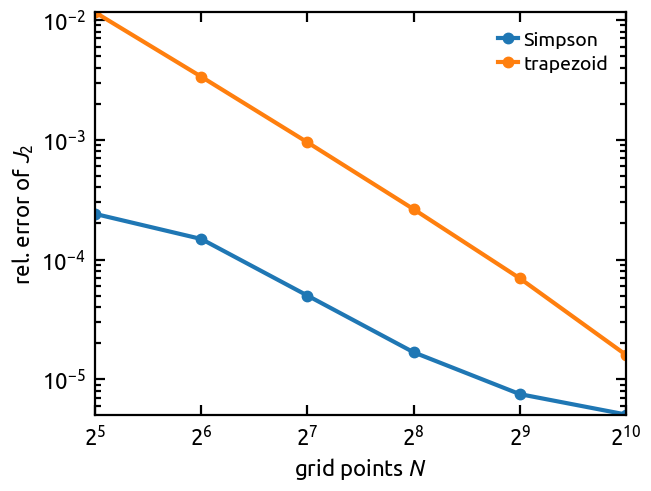

In [5]:
Ns_small = [2**k for k in range(5, 11)]
fig, ax = plt.subplots(layout="constrained")
for simpson in (True, False):
    errors = [rel_error(run(N, 4, use_simpson=simpson, repeat=1)[0], 1) for N in Ns_small]
    ax.plot(Ns_small, errors, "o-", label="Simpson" if simpson else "trapezoid")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("grid points $N$")
ax.set_ylabel("rel. error of $J_2$")
ax.legend(frameon=False)

Simpson's rule is only safe where the density is smooth. PyToF checks for two symptoms and then switches to the trapezoid rule for the rest of the calculation (`X.simpson_in_use` tells which rule is in use, `X.reset()` starts again with Simpson's rule): a non-equidistant grid, and a non-monotonic enclosed-mass function, which density jumps cause. Two situations are *not* caught:

* **Steep but smooth** features (a thin transition layer): Simpson's rule can then be *less* accurate than the trapezoid rule on a coarse grid. Compare both, or increase $N$ until they agree.
* **A density with an infinite slope at the surface**, such as polytropes with index $n<1$ ($\rho\propto (R-r)^n$): the iteration may then converge slowly or not at all. If `relax_to_barotrope()` runs into the iteration limit, try `use_simpson=False`:

In [6]:
def polytrope(n):
    X = ToF(N=1024, order=4, R_ref=JUPITER_RADIUS, baro_param=[n])
    X.set_barotrope(lambda P, param: P ** (param[0] / (param[0] + 1)))
    return X

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for n in (1.0, 0.8):
        for simpson in (True, False):
            X = polytrope(n)
            X.opts["use_simpson"] = simpson
            print(f"n = {n}, use_simpson = {simpson!s:5}: {X.relax_to_barotrope():3d} iterations")

n = 1.0, use_simpson = True :  17 iterations
n = 1.0, use_simpson = False:  17 iterations


n = 0.8, use_simpson = True : 100 iterations
n = 0.8, use_simpson = False:  19 iterations


## Tolerances

The iteration stops when the relative change of the moments, the densities and the rotational parameter falls below `dJ_tol`, `drho_tol` and `drot_tol` (default $10^{-10}$ each). There is nothing to gain from a tolerance far below the numerical error of the setting (previous sections: usually $10^{-6}$ to $10^{-9}$ for good settings), but a tolerance far above costs accuracy. For a calculation where you only need a few digits — scans, sampling — loosening it saves time:

In [7]:
reference, _, _ = run(1024, 7, dJ_tol=1e-12, drot_tol=1e-12, drho_tol=1e-12, repeat=1)
print(f"{'tolerance':>10s}{'iterations':>12s}{'time [s]':>10s}{'max|dJ/J|':>12s}")
for tol in (1e-4, 1e-6, 1e-8, 1e-10):
    X, t, it = run(1024, 7, dJ_tol=tol, drot_tol=tol, drho_tol=tol)
    print(f"{tol:10.0e}{it:12d}{t:10.3f}{np.max(np.abs(X.Js[1:] / reference.Js[1:] - 1)):12.1e}")

 tolerance  iterations  time [s]   max|dJ/J|


     1e-04           8     0.094     1.4e-05


     1e-06          11     0.134     1.9e-07


     1e-08          14     0.173     2.8e-09


     1e-10          18     0.221     9.1e-12


The achieved error is about the tolerance; the number of iterations falls from 18 to 8 for $10^{-10} \to 10^{-4}$. The iteration *limits* (`max_iter_barotrope`, `max_iter_density`, `max_iter_shape`, `max_iter_update`) must be at least 2; hitting one issues a `ConvergenceWarning`.

## Warnings

PyToF reports problems with Python's `warnings` module, so you decide what happens with them. They all derive from `PyToFWarning`:

| class | meaning |
|---|---|
| `ConvergenceWarning` | an iteration hit its limit before reaching the tolerance; the result is the last iterate |
| `RenamedWarning` | you used an old name (an option, an attribute) that still works but will be removed |
| `PyToFWarning` | everything else: inconsistent radius, no error estimate available, ... |

Messages that are not problems (assumptions made, fallbacks, timings) are printed only for `verbosity >= 1`. The three warning classes in action:

In [8]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")

    X = ToF(N=256, max_iter_barotrope=3)  # a limit that is too small
    X.set_barotrope(lambda P, param: np.sqrt(P))
    X.relax_to_barotrope()

    ToF(MaxIterBar=50)  # old option name, from PyToF <= 1.7

    X = ToF(N=256, alphas=np.r_[1e5, np.zeros(11)])
    X.get_Js_errors()  # no error estimates for differential rotation

for w in caught:
    print(f"{w.category.__name__:18s}{str(w.message)[:90]}")

ConvergenceWarningdrot = 1e-03 > 1e-10, dJ = 5e-01 > 1e-10, drho = 1e-03 > 1e-10 after max_iter_barotrope = 
RenamedWarning    The option 'MaxIterBar' was renamed to 'max_iter_barotrope'. The old name still works but 
PyToFWarning      Accuracy when using differential rotation is unknown. PyToF provides no error estimates.


To silence one kind, ignore its class; to be strict, turn it into an error (useful in scripts where a non-converged model must not go unnoticed):

```python
warnings.filterwarnings("ignore", category=RenamedWarning)
warnings.filterwarnings("error", category=ConvergenceWarning)
```

## Debugging: `debug_plot`

If a calculation does not converge or gives odd results, `debug_plot=True` saves figures of the density and pressure profiles of every iteration and of the intermediate quantities of the Theory of Figures into the **current working directory** (matplotlib is only imported in this case). It is slow, produces many files, and is meant for short runs with a small `N`. A short demonstration in a temporary directory:

28 figures written, e.g.:
  debug_AlgoToF_integral_0.png
  debug_AlgoToF_integral_1.png
  debug_AlgoToF_integral_2.png
  debug_AlgoToF_integral_3.png


Text(0.5, 1.0, 'debug_FunctionsToF_rho_*.png: density, one curve per iteration')

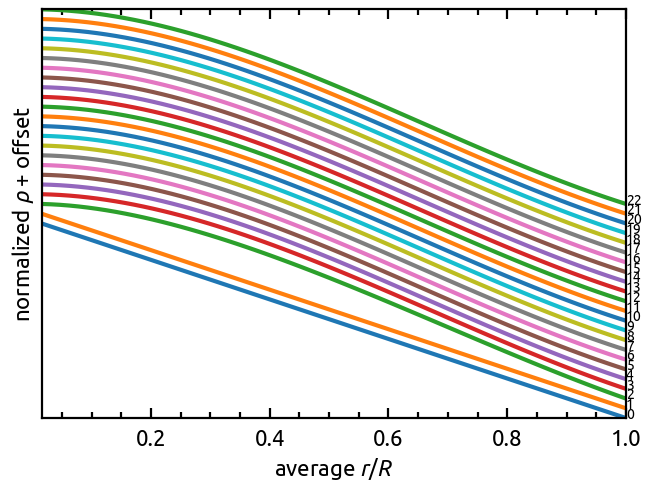

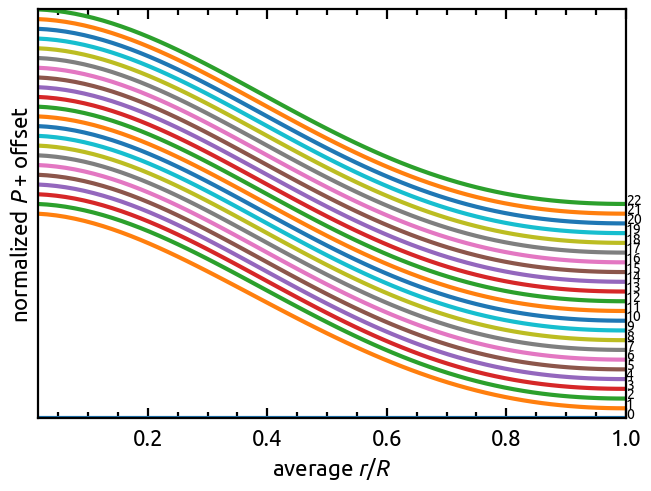

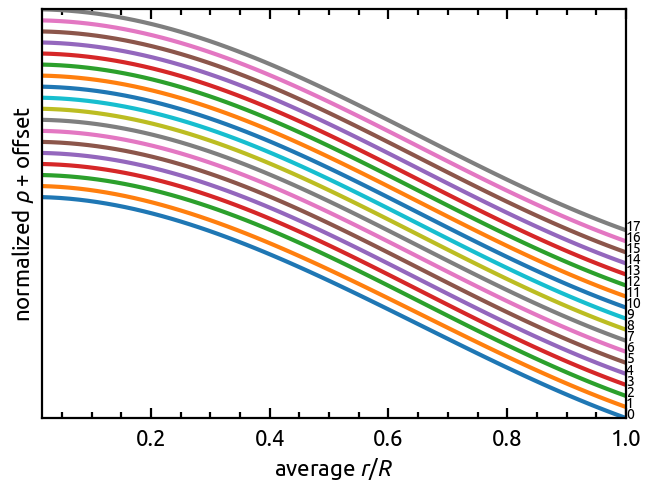

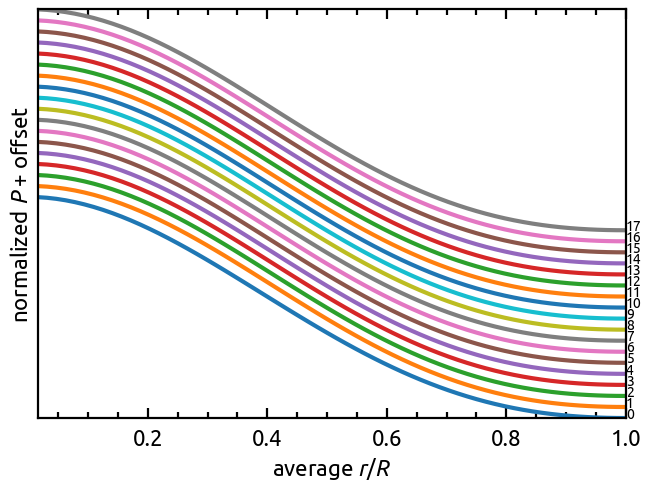

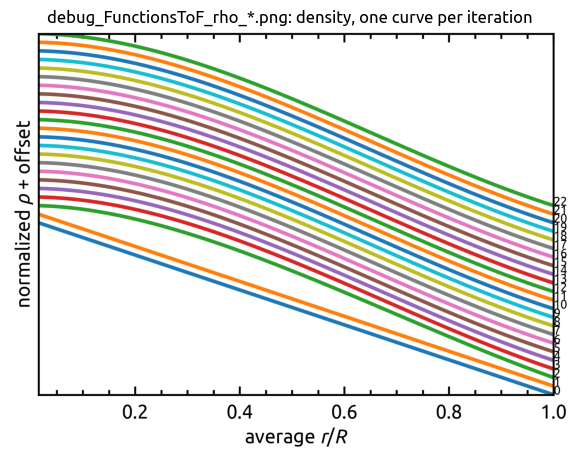

In [9]:
start = os.getcwd()
with tempfile.TemporaryDirectory() as tmp:
    os.chdir(tmp)
    try:
        X = ToF(N=64, order=4, R_ref=JUPITER_RADIUS, debug_plot=True, max_iter_barotrope=3)
        X.set_barotrope(lambda P, param: np.sqrt(P))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            X.relax_to_barotrope()
        files = sorted(pathlib.Path(tmp).glob("*.png"))
        print(f"{len(files)} figures written, e.g.:", *[f.name for f in files[:4]], sep="\n  ")
        image = plt.imread(next(f for f in files if f.name.startswith("debug_FunctionsToF_rho")))
    finally:
        os.chdir(start)

fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
ax.imshow(image)
ax.axis("off")
ax.set_title("debug_FunctionsToF_rho_*.png: density, one curve per iteration")

## Takeaways: recommended settings

| goal | order | $N$ | other |
|---|---|---|---|
| quick look, $J_2$ to $10^{-4}$ | 4 | 128 | defaults |
| $J_2$ to $10^{-5}$, $J_4$ to $10^{-4}$ | 4–7 | 256–512 | defaults |
| $J_2$, $J_4$ to $10^{-6}$ | 7 | 1024 | defaults |
| $J_6$ to $10^{-6}$ or better, $J_8$ and higher | 10 | 256 and up | `n_bin=N//16` for $N \gtrsim 4096$ |
| scans, sampling | 4 | 128–256 | `dJ_tol`, `drho_tol`, `drot_tol` ~ the accuracy you need |
| profile with density jumps | any | enough points to resolve the jumps | `use_simpson=False` saves the failed attempt |

1. Choose the **order** by the highest moment you need, then the **grid** by the accuracy you need; check by repeating with the next larger `N`.
2. Use `get_Js_errors()` (solid body rotation) as a guide, but verify unusual profiles yourself.
3. Treat a `ConvergenceWarning` as a real problem: look at the numbers in the message, then try `use_simpson=False`, a larger `max_iter_*`, or a smaller `N`.